# 04 · The backtest: does the Replacement Finder beat simple scouting rules?

Notebooks 02 and 03 built two ingredients: a **style similarity** score and a **growth model**. The Replacement Finder
(`src/finder.py`) combines them. When a club sells a player, it:

1. finds all players of the same (or a neighboring) role who fit the **budget**, the **wage cap** and an **age limit**;
2. keeps only the half of them whose **playing style** is most similar to the sold player;
3. ranks the rest by their **predicted rating in two years**.

A list of names proves nothing, though. Any method produces a list. The question the task asks is:
**is our list better than a simple rating, and can we trust that?**

This notebook answers it with a **backtest**: we go back in time, make hundreds of transfer decisions with old data,
and check what happened to the chosen players afterwards.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, str(Path("../src").resolve()))   # our own modules live in src/
import plot_style
from plot_style import BLUE, ORANGE, AQUA, INK_2, MUTED, EURO, euro

plot_style.apply()
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)

from backtest import FINDER, SYSTEMS, bootstrap_difference, run_backtest, summarize
from finder import ReplacementFinder, load_players

players = load_players()
CACHE = Path("../data/processed/backtest_picks.parquet")
RECOMPUTE = False   # set to True after changing src/finder.py or src/backtest.py

## 1. How the backtest works

**Time travel.** We stand at the end of FIFA 19 (summer 2019), FIFA 20 (summer 2020) and FIFA 21 (summer 2021). At each moment
the Finder's growth model is retrained using **only** data known at that time. Then we look two seasons ahead (FIFA 21, 22 and 23)
to see how the picks turned out. FIFA 23's last update is from January 2023, so the last group is checked mid-season.

**Many cases, not one.** One case could be lucky. So in each season we pick **250 random "sold" players**: established
first-division players rated 70–84, aged 22–30. That's 750 transfer decisions in total.

**The same rules for everyone.** For each case, every method chooses **5 replacements** from the **same pool** of candidates:

- same or neighboring role as the sold player,
- price at most **60% of the sold player's value** (we're a Moneyball club: we sell high and buy cheaper),
- wage at most the sold player's wage,
- age at most 28,
- rated at most 12 points below the sold player today.

**The methods we compare:**

| Method | How it picks the 5 players |
|---|---|
| **Finder (style filter + growth model)** | Our system: best style half, then highest predicted rating in 2 years |
| Finder, minimum style match 0.6 | Same, but also demands a style similarity of at least 0.6 |
| Finder, prefer cheaper | Same, but 30% of the score rewards a lower price |
| Growth model only | Highest predicted rating, ignoring style |
| First design | Our first attempt: 40% style + 40% future + 20% price, all mixed into one score |
| Highest overall | What a basic scout does: the best current rating he can afford |
| Highest potential | The "buy young talent" rule: the highest EA potential he can afford |
| Random | Five random players from the pool, as a floor |

**What counts as success?** Two years later, the pick is **still in the game** and rated **at most 3 points below the sold
player**. In other words, he became a real replacement. Players who disappeared from the game count as failures. This
matters: notebook 01 showed that about 38% of players disappear within two years, and ignoring them would make every
method look better than it is (**survivorship bias**).

In [2]:
if CACHE.exists() and not RECOMPUTE:
    picks = pd.read_parquet(CACHE)
else:
    finders = {v: ReplacementFinder(players, v) for v in (19, 20, 21)}
    picks = run_backtest(players, decision_versions=(19, 20, 21), n_cases=250, finders=finders)
    picks.to_parquet(CACHE)

print(f"{picks.case.nunique()} transfer cases, {len(picks):,} picks")
print(f"Median candidate pool: {picks.groupby('case').pool_size.first().median():.0f} players")

750 transfer cases, 30,000 picks
Median candidate pool: 1226 players


## 2. Results

In [3]:
results = summarize(picks)
nice = results.rename(columns={
    "success": "Success rate", "overall_2y": "Avg rating in 2 years (if still in game)",
    "dropout": "Dropped out", "fit": "Style similarity", "cost_m": "Avg price (€M)",
    "value_change": "Median value change (log)",
})
nice.style.format({
    "Success rate": "{:.1%}", "Avg rating in 2 years (if still in game)": "{:.1f}", "Dropped out": "{:.1%}",
    "Style similarity": "{:.2f}", "Avg price (€M)": "{:.2f}", "Median value change (log)": "{:+.2f}",
})

,Success rate,Avg rating in 2 years (if still in game),Dropped out,Style similarity,Avg price (€M),Median value change (log)
system,,,,,,
Finder (style filter + growth model),56.1%,71.9,13.1%,0.74,3.83,+0.36
"Finder, minimum style match 0.6",53.2%,71.7,14.4%,0.78,3.74,+0.30
"Finder, prefer cheaper (price weight 0.3)",41.0%,70.9,17.7%,0.74,2.74,+0.57
Growth model only (no style filter),57.7%,72.1,13.9%,0.63,3.87,+0.43
First design (fit .4 / future .4 / price .2),36.4%,70.4,18.9%,0.84,2.88,+0.26
Highest overall,42.9%,70.9,19.9%,0.60,3.87,-0.32
Highest potential,43.9%,70.6,7.0%,0.64,2.58,+0.91
Random,11.1%,67.3,31.9%,0.62,1.42,+0.21


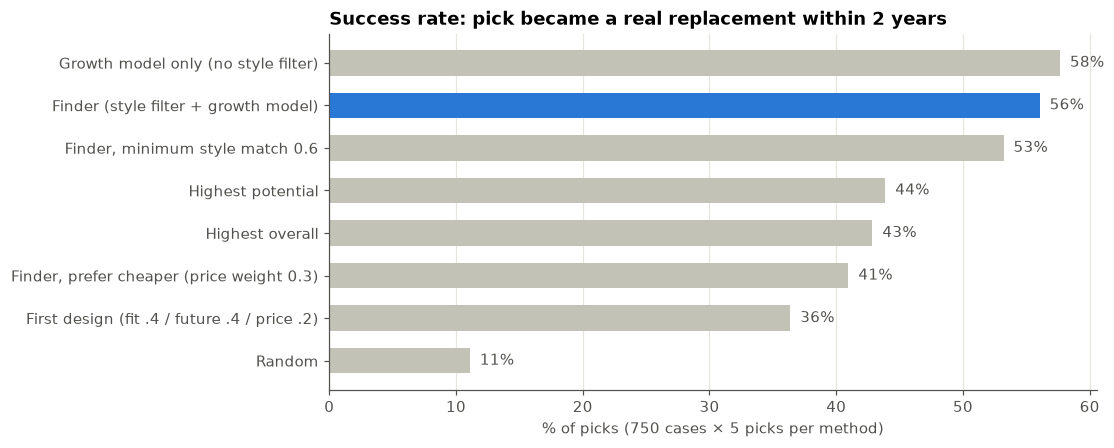

In [4]:
order = results.success.sort_values()
colors = [BLUE if name == FINDER else MUTED for name in order.index]

fig, ax = plt.subplots(figsize=(9, 4.2))
ax.barh(order.index, order.values * 100, color=colors, height=0.6)
for name, v in order.items():
    ax.text(v * 100, name, f"  {v:.0%}", va="center", color=INK_2)
ax.grid(axis="y", visible=False)
ax.set(title="Success rate: pick became a real replacement within 2 years",
       xlabel="% of picks (750 cases × 5 picks per method)")
plt.show()

**How to read this.** The Finder turns about 56% of its picks into real replacements. A basic scout who buys the highest
rating he can afford manages about 43%, and EA's potential about 44%. Random picks manage only about 11%, which shows how
hard the task is: the budget is only 60% of the sold player's price.

Look at the other columns too. They show **why** the Finder wins:

- Its picks reach a **higher rating two years later**, so the growth model really sees the future better than today's rating.
- **Fewer of them disappear** from the game than the "highest overall" picks.
- They have a clearly **better style match** than the simple rules, so they're more likely to do the same job in the team.
- They cost about the **same** as the "highest overall" picks. The Finder doesn't win by spending more.
- Their **market value grows**, while the "highest overall" picks lose value. Those are often players at their peak who are
  about to decline.

Our **first design** (mixing 40% style into the score) is the worst of the smart methods. It sacrificed too much quality
for style similarity. That's why we changed the design to "style as a filter, growth model for ranking". The backtest
showed us the mistake, which is exactly what a backtest is for.

### Is the difference real or luck?

750 cases is a lot, but we should still check whether the advantage could be chance. We use the **bootstrap**. We resample
the 750 cases with replacement thousands of times and recompute the difference each time. The middle 95% of those
differences is a **95% confidence interval**. If the whole interval is above zero, the advantage is very unlikely to be luck.

We resample whole cases, not single picks, because the 5 picks of one case share the same sold player and pool, so they're
not independent.

In [5]:
rows = []
for rival in ["Highest overall", "Highest potential", "Growth model only (no style filter)"]:
    for metric, label in [("success", "success rate"), ("still_in_game", "still in game")]:
        mean, low, high = bootstrap_difference(picks, metric, FINDER, rival)
        rows.append({"Finder vs": rival, "metric": label,
                     "difference": f"{mean:+.1%}", "95% interval": f"[{low:+.1%}, {high:+.1%}]"})
pd.DataFrame(rows)

,Finder vs,metric,difference,95% interval
0,Highest overall,success rate,+13.2%,"[+10.9%, +15.4%]"
1,Highest overall,still in game,+6.8%,"[+5.1%, +8.6%]"
2,Highest potential,success rate,+12.2%,"[+10.2%, +14.2%]"
3,Highest potential,still in game,-6.1%,"[-7.3%, -4.8%]"
4,Growth model only (no style filter),success rate,-1.6%,"[-2.9%, -0.3%]"
5,Growth model only (no style filter),still in game,+0.8%,"[-0.2%, +1.8%]"


Against both simple rules, the Finder's advantage in success rate stays clearly above zero across the whole confidence
interval. That's not luck.

Against the **growth model without the style filter**, the Finder is about 1.6 points *lower*, and the interval is just below
zero. So the style filter has a small but real cost. In exchange, it gives a much better style match (0.74 vs 0.63 in the table
above). For a club, a replacement who does the same job in the team is worth that small cost, so we keep the filter. The app
lets the user switch it off.

## 3. Robustness: does the result depend on our choices?

A result that only holds for one particular setup is fragile. We change the setup in three ways and check whether the Finder
still wins.

### 3a. Different seasons

In [6]:
main = [FINDER, "Highest overall", "Highest potential", "Random"]
by_season = picks[picks.system.isin(main)].groupby(["version", "system"]).success.mean().unstack()[main]
by_season.index = [f"Decision at end of FIFA {v}" for v in by_season.index]
by_season.style.format("{:.1%}")

system,Finder (style filter + growth model),Highest overall,Highest potential,Random
Decision at end of FIFA 19,57.0%,41.5%,44.6%,12.2%
Decision at end of FIFA 20,61.6%,39.7%,56.8%,11.0%
Decision at end of FIFA 21,49.6%,47.4%,30.2%,10.1%


The Finder is the best method in every season, not just on average. In the last season its lead over "highest overall" is
small (about 2 points). Those outcomes are measured in January 2023, only one and a half seasons later, so young players
had less time to grow. That's exactly the kind of player the Finder prefers.

### 3b. A stricter or looser definition of success

We defined success as "at most 3 points below the sold player". What if we demand an equally good player (0 points below),
or accept up to 5 points below?

In [7]:
rows = {}
for gap in [0, 3, 5]:
    ok = picks.still_in_game & (picks.overall_2y >= picks.sold_overall - gap)
    rows[f"at most {gap} below"] = ok.groupby(picks.system).mean()
pd.DataFrame(rows).loc[list(SYSTEMS)].style.format("{:.1%}")

,at most 0 below,at most 3 below,at most 5 below
system,,,
Finder (style filter + growth model),21.6%,56.1%,75.0%
"Finder, minimum style match 0.6",19.7%,53.2%,73.1%
"Finder, prefer cheaper (price weight 0.3)",16.6%,41.0%,60.0%
Growth model only (no style filter),23.2%,57.7%,75.3%
First design (fit .4 / future .4 / price .2),12.0%,36.4%,56.3%
Highest overall,10.3%,42.9%,66.2%
Highest potential,21.0%,43.9%,60.8%
Random,3.1%,11.1%,21.9%


The numbers change (stricter is harder for everyone), but the Finder stays clearly ahead of "highest overall" under every
definition. At the strictest level ("as good as the sold player"), it's practically tied with "highest potential": finding a
player who becomes *fully* as good with only 60% of the money mostly means betting on very young talent, and that's what the
potential rule does.

### 3c. A 20% smaller budget

The task asks: what if the budget drops by 20%? We rerun the backtest with the budget at 48% of the sold player's value
instead of 60%, for the main methods.

In [8]:
CACHE_SMALL = Path("../data/processed/backtest_picks_budget48.parquet")
if CACHE_SMALL.exists() and not RECOMPUTE:
    picks_small = pd.read_parquet(CACHE_SMALL)
else:
    finders = {v: ReplacementFinder(players, v) for v in (19, 20, 21)}
    picks_small = run_backtest(players, decision_versions=(19, 20, 21), n_cases=250, finders=finders,
                               budget_factor=0.48, systems={k: SYSTEMS[k] for k in main})
    picks_small.to_parquet(CACHE_SMALL)

compare = pd.DataFrame({
    "budget 60%": picks[picks.system.isin(main)].groupby("system").success.mean(),
    "budget 48% (−20%)": picks_small.groupby("system").success.mean(),
}).loc[main]
compare["change"] = compare["budget 48% (−20%)"] - compare["budget 60%"]
compare.style.format("{:+.1%}", subset=["change"]).format("{:.1%}", subset=["budget 60%", "budget 48% (−20%)"])

,budget 60%,budget 48% (−20%),change
system,,,
Finder (style filter + growth model),56.1%,43.3%,-12.7%
Highest overall,42.9%,29.8%,-13.0%
Highest potential,43.9%,37.2%,-6.7%
Random,11.1%,8.1%,-3.0%


With less money, every method finds fewer real replacements, since the best candidates become unaffordable. The Finder
**stays the best method**: its lead over "highest overall" stays at about 13 points. Its lead over "highest potential" shrinks
to about 6 points, because a smaller budget pushes every method toward young, cheap players, where the two approaches pick
more similar names.

## 4. Trade-offs a club can choose

The backtest also shows that different methods serve different goals:

- **"Minimum style match 0.6"** demands a closer copy of the sold player. It gives up about 3 points of success rate for a
  better style match. That's useful for rare player types: for a classic playmaker like Eriksen, half of all candidates have
  almost nothing in common with him, so "the better half" isn't enough (see notebook 05).

- **"Prefer cheaper" (price weight 0.3)** spends about 28% less per player (€2.7M instead of €3.8M), but its success rate falls
  from about 56% to about 41%. Saving money is possible, but it isn't free. The Streamlit app lets the sporting director choose
  this balance with a slider.
- **"Highest potential"** has a low success rate as a *replacement*, but the highest growth in market value and the fewest
  drop-outs. These are very young players: a good **resale** strategy (buy, develop, sell), but not a way to replace a first-team
  player right now.

## 5. One case, up close

Numbers over 750 cases are convincing, but a single example makes it concrete. Here is one case, with the 5 picks of the Finder
and of "highest overall", and how they turned out:

In [9]:
case_success = picks.pivot_table(index="case", columns="system", values="success", aggfunc="mean")
finder_fit = picks[picks.system == FINDER].groupby("case").fit.mean()
gain = (case_success[FINDER] - case_success["Highest overall"])[finder_fit >= 0.8]   # cases with a real style match
example = gain.idxmax()

sold_id = picks.loc[picks.case == example, "sold_id"].iat[0]
version = int(example.split("-")[0])
sold = players[(players.player_id == sold_id) & (players.fifa_version == version)].iloc[0]
print(f"FIFA {version}: selling {sold.short_name} ({sold.club_name}), {sold.main_position}, "
      f"rated {sold.overall:.0f}, value {euro(sold.value_eur)}, budget {euro(0.6 * sold.value_eur)}")

names = players[players.fifa_version == version].set_index("player_id").short_name
view = picks[(picks.case == example) & picks.system.isin([FINDER, "Highest overall"])].copy()
view["player"] = view.player_id.map(names)
view[["system", "player", "age", "overall", "value_eur", "fit", "overall_2y", "success"]].round(2)

FIFA 19: selling N. Nikolić (Chicago Fire), ST, rated 73, value €3.9M, budget €2.34M


,system,player,age,overall,value_eur,fit,overall_2y,success
5480,Finder (style filter + growth model),M. Barrow,19.0,69.0,2300000.0,0.82,75.0,True
5481,Finder (style filter + growth model),E. Håland,17.0,68.0,1800000.0,0.83,87.0,True
5482,Finder (style filter + growth model),I. Niane,19.0,69.0,2000000.0,0.85,72.0,True
5483,Finder (style filter + growth model),J. Hurtado,18.0,69.0,2200000.0,0.83,NaN,False
5484,Finder (style filter + growth model),M. Romero,19.0,69.0,2300000.0,0.89,70.0,True
5505,Highest overall,M. Pedersen,28.0,70.0,1800000.0,0.83,NaN,False
5506,Highest overall,T. Necid,28.0,70.0,1800000.0,0.87,NaN,False
5507,Highest overall,K. Barbarouses,28.0,70.0,1800000.0,0.79,69.0,False
5508,Highest overall,K. Sigþórsson,28.0,70.0,1800000.0,0.75,67.0,False
5509,Highest overall,B. Mokulu,28.0,70.0,1800000.0,0.75,NaN,False


Look at the second Finder pick: a **17-year-old Norwegian striker rated 68, for €1.8M. That's Erling Haaland**, who was rated
87 two years later and became one of the best strikers in the world. The Finder, using only data from summer 2019, put him on
a five-name shortlist to replace a Chicago Fire striker. The "highest overall" scout bought five 28-year-olds rated 70; three
of them were out of the game two years later, and none became a real replacement.

To be fair: we chose this case *because* it looks good (one of the cases most in the Finder's favor among those with a real
style match), so it's a showcase, not a typical case. The 750-case results above are the real evidence. The pattern is typical, though:
"highest overall" buys players who are good **now** but often older or at their peak, while the Finder buys players who are
slightly worse today but **still improving**, and who play in the same style.

## Summary

| Question | Answer |
|---|---|
| Is the Finder better than simple rules? | Yes: ~56% success vs ~43–44% for "highest overall" / "highest potential", ~11% for random |
| Is it luck? | No, the 95% bootstrap interval of the advantage is clearly above zero |
| Why does it win? | Higher rating 2 years later, fewer drop-outs, much better style match, at the same price |
| Does it hold in every season? | Yes, best in each of the three decision seasons (narrowly in the last, mid-season one) |
| Does it depend on the success definition? | Ahead of "highest overall" for 0, 3 and 5 points; tied with "highest potential" at the strictest level |
| What if the budget is 20% smaller? | Everyone gets worse; the Finder stays best (+13 vs highest overall, +6 vs highest potential) |
| What does the style filter cost? | About 1.6 points of success, for a much better style match (0.74 vs 0.63) |
| Can we save money? | Yes: "prefer cheaper" spends ~28% less but succeeds ~41% instead of ~56% |
| What did we learn from failures? | Our first design (style mixed into the score) was worse; style works better as a filter |
| Remaining limits | Ratings are EA's opinion, not match data; FIFA 23 outcomes are mid-season; "success" ignores how the player fits a specific coach |

**Next:** notebook 05 uses the Finder for real decisions in summer 2022 and compares its suggestions with what clubs actually did.